In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

In [3]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train_cnn = x_train.reshape(-1,28,28,1)
x_test_cnn = x_test.reshape(-1,28,28,1)

x_train_mlp = x_train.reshape(-1,784)
x_test_mlp = x_test.reshape(-1,784)

In [4]:
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

mlp.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

mlp.fit(x_train_mlp, y_train, epochs=3, batch_size=64)

mlp_loss, mlp_acc = mlp.evaluate(x_test_mlp, y_test)

print("MLP Accuracy:", mlp_acc)

Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9191 - loss: 0.2830
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9661 - loss: 0.1148
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9760 - loss: 0.0788
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9733 - loss: 0.0869
MLP Accuracy: 0.9732999801635742


In [5]:
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),

    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

In [6]:
cnn.fit(x_train_cnn, y_train, epochs=3, batch_size=64)

cnn_loss, cnn_acc = cnn.evaluate(x_test_cnn, y_test)

print("CNN Accuracy:", cnn_acc)

Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 27s 26ms/step - accuracy: 0.9173 - loss: 0.2622
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - accuracy: 0.9691 - loss: 0.1008
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.9765 - loss: 0.0765
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9858 - loss: 0.0443
CNN Accuracy: 0.98580002784729


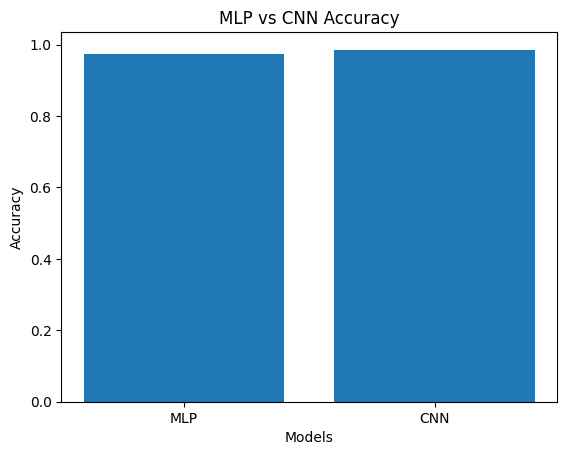

In [7]:
models = ['MLP', 'CNN']
accuracies = [mlp_acc, cnn_acc]

plt.bar(models, accuracies)
plt.title("MLP vs CNN Accuracy")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.show()

In [8]:
print("MLP Accuracy:", mlp_acc)
print("CNN Accuracy:", cnn_acc)

MLP Accuracy: 0.9732999801635742
CNN Accuracy: 0.98580002784729


In [9]:
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']

x_test = data['x_test']
y_test = data['y_test']